<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week13_Classification_Performance_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# for data handling
import numpy as np
import pandas as pd

# visualization
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
df = pd.read_csv("/content/drive/MyDrive/데이터마이닝수업/Data/default_credit_card.csv", index_col='Cust_ID')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 30000 entries, 1 to 30000
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   LIMIT_BAL   30000 non-null  int64
 1   SEX         30000 non-null  int64
 2   EDUCATION   30000 non-null  int64
 3   MARRIAGE    30000 non-null  int64
 4   AGE         30000 non-null  int64
 5   PAY_0       30000 non-null  int64
 6   PAY_2       30000 non-null  int64
 7   PAY_3       30000 non-null  int64
 8   PAY_4       30000 non-null  int64
 9   PAY_5       30000 non-null  int64
 10  PAY_6       30000 non-null  int64
 11  BILL_AMT1   30000 non-null  int64
 12  BILL_AMT2   30000 non-null  int64
 13  BILL_AMT3   30000 non-null  int64
 14  BILL_AMT4   30000 non-null  int64
 15  BILL_AMT5   30000 non-null  int64
 16  BILL_AMT6   30000 non-null  int64
 17  PAY_AMT1    30000 non-null  int64
 18  PAY_AMT2    30000 non-null  int64
 19  PAY_AMT3    30000 non-null  int64
 20  PAY_AMT4    30000 non-null  int64

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_YN
Cust_ID,,,,,,,,,,,,,,,,,,,,,
1,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [27]:
cate_columns = ['SEX', 'EDUCATION', 'MARRIAGE']

for col in cate_columns:
    print(f"=== {col} Value Counts (including missing values) ===")
    print(df[col].value_counts(dropna=False))
    print("\n")

=== SEX Value Counts (including missing values) ===
SEX
2    18112
1    11888
Name: count, dtype: int64


=== EDUCATION Value Counts (including missing values) ===
EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64


=== MARRIAGE Value Counts (including missing values) ===
MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64




In [28]:
# cate_columns 대상 원핫 인코딩(One-Hot Encoding) 처리
df_encoded = pd.get_dummies(df, columns=cate_columns, dtype=int)

# 변환 결과 확인
print(df_encoded.info())
df_encoded.head()

<class 'pandas.core.frame.DataFrame'>
Index: 30000 entries, 1 to 30000
Data columns (total 34 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   LIMIT_BAL    30000 non-null  int64
 1   AGE          30000 non-null  int64
 2   PAY_0        30000 non-null  int64
 3   PAY_2        30000 non-null  int64
 4   PAY_3        30000 non-null  int64
 5   PAY_4        30000 non-null  int64
 6   PAY_5        30000 non-null  int64
 7   PAY_6        30000 non-null  int64
 8   BILL_AMT1    30000 non-null  int64
 9   BILL_AMT2    30000 non-null  int64
 10  BILL_AMT3    30000 non-null  int64
 11  BILL_AMT4    30000 non-null  int64
 12  BILL_AMT5    30000 non-null  int64
 13  BILL_AMT6    30000 non-null  int64
 14  PAY_AMT1     30000 non-null  int64
 15  PAY_AMT2     30000 non-null  int64
 16  PAY_AMT3     30000 non-null  int64
 17  PAY_AMT4     30000 non-null  int64
 18  PAY_AMT5     30000 non-null  int64
 19  PAY_AMT6     30000 non-null  int64
 20  default_YN 

,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,...,EDUCATION_1,EDUCATION_2,EDUCATION_3,EDUCATION_4,EDUCATION_5,EDUCATION_6,MARRIAGE_0,MARRIAGE_1,MARRIAGE_2,MARRIAGE_3
Cust_ID,,,,,,,,,,,,,,,,,,,,,
1,20000,24,2,2,-1,-1,-2,-2,3913,3102,...,0,1,0,0,0,0,0,1,0,0
2,120000,26,-1,2,0,0,0,2,2682,1725,...,0,1,0,0,0,0,0,0,1,0
3,90000,34,0,0,0,0,0,0,29239,14027,...,0,1,0,0,0,0,0,0,1,0
4,50000,37,0,0,0,0,0,0,46990,48233,...,0,1,0,0,0,0,0,1,0,0
5,50000,57,-1,0,-1,0,0,0,8617,5670,...,0,1,0,0,0,0,0,1,0,0


### 학습(Train) 데이터: 70%,  검증(Test) 데이터: 30%

In [29]:
# 데이터프레임을 train 데이터셋과 test 데이터셋으로 분리 (70:30 비율)

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.3, random_state=2421) # random_state는 일정한 결과를 얻기위해 설정

# 분리된 데이터셋 확인 (선택 사항)
print("Train dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

Train dataset shape: (21000, 24)
Test dataset shape: (9000, 24)


### 학습(Trining) 및 예측성능평가

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# 설명 변수와 목표 변수 설정
X_train = train_df.drop(['default_YN'], axis=1)
y_train = train_df['default_YN']
X_test = test_df.drop(['default_YN'], axis=1)
y_test = test_df['default_YN']

# 실행할 수 있는 후보 모델 정의
models = {
    'logistic_regression': LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=345, max_iter=1000),
    'svm': SVC(probability=True, random_state=2345, kernel='rbf'),  # 예측 확률 시각화를 위해 probability=True 설정
    'random_forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=2345, n_jobs=-1),
    'boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=10, random_state=2345)
}

# [선택] 실행하고자 하는 알고리즘명을 입력하세요: 'logistic_regression', 'svm', 'random_forest', 'boosting'
selected_model_name = 'logistic_regression'

# 선택된 모델 로드
model = models[selected_model_name]
print(f"Selected Model: {selected_model_name}\n")

# 모델 학습
model.fit(X_train, y_train)

# 예측 (기본 Threshold: 0.5)
threshold = 0.5
y_pred = (model.predict_proba(X_test)[:, 1] >= threshold).astype(bool)

# 모델 평가
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")
print(classification_report(y_test, y_pred))

Selected Model: logistic_regression

Accuracy: 0.8126666666666666
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      7011
           1       0.73      0.24      0.36      1989

    accuracy                           0.81      9000
   macro avg       0.77      0.61      0.63      9000
weighted avg       0.80      0.81      0.77      9000



### Class별 예측확률(p) 분포

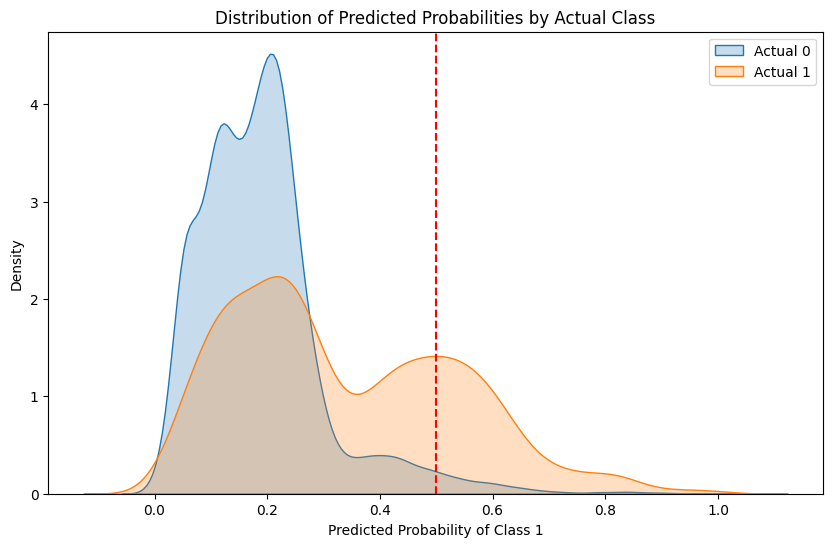

In [31]:
# 예측 확률 얻기
y_pred_proba = model.predict_proba(X_test)

# 클래스 0과 1에 대한 예측 확률 분포 시각화
plt.figure(figsize=(10, 6))

sns.kdeplot(y_pred_proba[y_test == 0, 1], label='Actual 0', fill=True)
sns.kdeplot(y_pred_proba[y_test == 1, 1], label='Actual 1', fill=True)


# Add vertical lines
plt.axvline(x=threshold, color='red', linestyle='--')

plt.xlabel('Predicted Probability of Class 1')
plt.ylabel('Density')
plt.title('Distribution of Predicted Probabilities by Actual Class')
plt.legend()
plt.show()

### Confusion Matrix

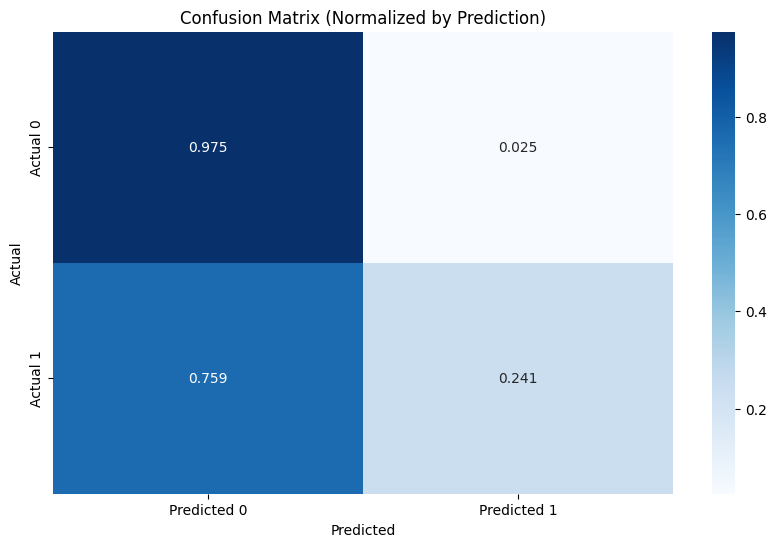

In [32]:
from sklearn.metrics import confusion_matrix

# Confusion matrix 생성 (예측값 기준 정규화)
cm = confusion_matrix(y_test, y_pred, normalize='true')

# Confusion matrix 시각화 (소수점 둘째 자리까지 표기 설정: fmt='.2f')
plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt='.3f', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Normalized by Prediction)')
plt.show()

### ROC Curve

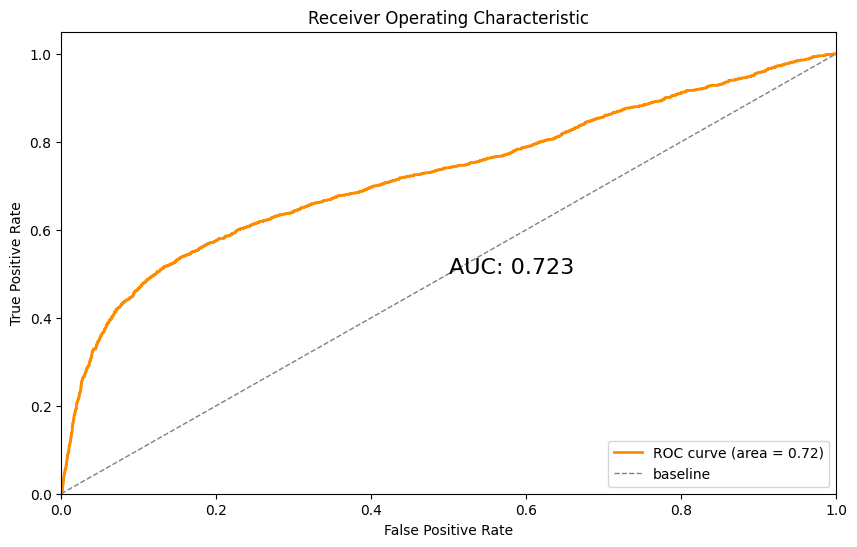

In [33]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# 예측 확률 얻기
y_pred_proba = model.predict_proba(X_test)[:, 1]

# ROC Curve 계산
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# AUC 계산
roc_auc = auc(fpr, tpr)

# ROC Curve 시각화
plt.figure(figsize=(10,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='baseline')

# 오류 수정: roc_auc_score 함수를 임포트하고, 정의된 y_pred_proba 변수를 사용합니다.
plt.text(0.5, 0.5, f"AUC: {roc_auc:.3f}", fontsize=16)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

### Precision-Recall Curve

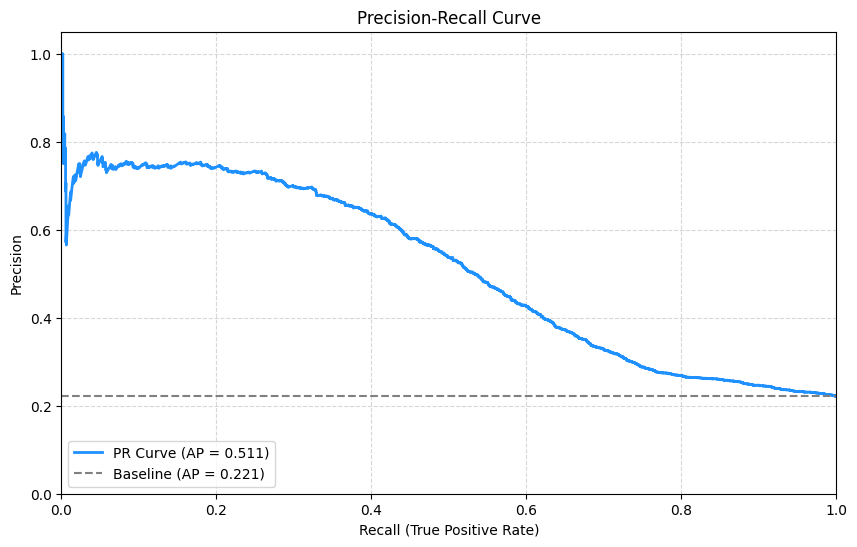

In [34]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# 1. Precision-Recall Curve 계산
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)

# 2. Average Precision (AP) 점수 계산
ap_score = average_precision_score(y_test, y_pred_proba)

# 3. Precision-Recall Curve 시각화
plt.figure(figsize=(10, 6))
plt.plot(recall, precision, color='dodgerblue', lw=2, label=f'PR Curve (AP = {ap_score:.3f})')

# 무작위 분류기(Baseline) 기준선 표시
no_skill = len(y_test[y_test == 1]) / len(y_test)
plt.axhline(y=no_skill, color='gray', linestyle='--', label=f'Baseline (AP = {no_skill:.3f})')

plt.xlabel('Recall (True Positive Rate)')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.show()

### PR Curve & F1 score

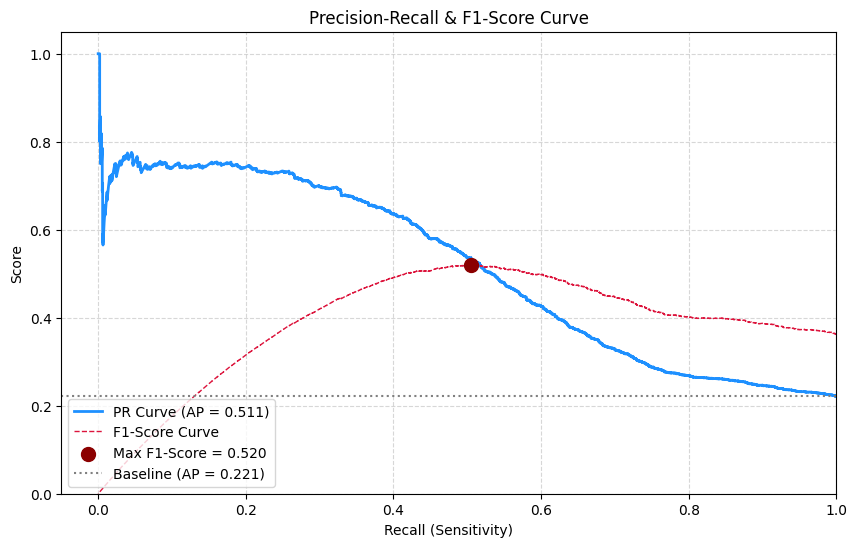

In [35]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import numpy as np

# 1. Precision-Recall Curve 계산
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)

# 2. F1-Score 계산 (분모가 0이 되는 것을 방지하기 위해 아주 작은 값 eps 추가)
eps = 1e-10
f1_scores = 2 * (precision * recall) / (precision + recall + eps)

# 3. Average Precision (AP) 점수 계산
ap_score = average_precision_score(y_test, y_pred_proba)

# 4. 시각화
plt.figure(figsize=(10, 6))

# Precision-Recall Curve 플롯
plt.plot(recall, precision, color='dodgerblue', lw=2, label=f'PR Curve (AP = {ap_score:.3f})')

# F1-Score 플롯
plt.plot(recall, f1_scores, color='crimson', lw=1.0, linestyle='--', label='F1-Score Curve')

# F1-Score 최댓값 지점 표시
max_f1_idx = np.argmax(f1_scores)
max_f1 = f1_scores[max_f1_idx]
corresponding_recall = recall[max_f1_idx]
corresponding_precision = precision[max_f1_idx]

plt.scatter(corresponding_recall, max_f1, color='darkred', s=100, zorder=5,
             label=f'Max F1-Score = {max_f1:.3f}')

# 무작위 분류기(Baseline) 기준선 표시
no_skill = len(y_test[y_test == 1]) / len(y_test)
plt.axhline(y=no_skill, color='gray', linestyle=':', label=f'Baseline (AP = {no_skill:.3f})')

plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Score')
plt.title('Precision-Recall & F1-Score Curve')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.show()

## Cross-Validation(교차검증)

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import pandas as pd
import numpy as np

# 1. Feature와 Target 분리 (Target은 'default_YN')
X = df_encoded.drop(columns=['default_YN'])
y = df_encoded['default_YN']

# 2. 교차 검증용 후보 모델 정의
cv_models = {
    'logistic_regression': LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=345, max_iter=1000),
    'svm': SVC(probability=True, random_state=2345, kernel='rbf'),
    'random_forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=2345, n_jobs=-1),
    'boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=10, random_state=2345)
}

# =========================================================================
# [선택] 평가할 알고리즘명을 변경하여 입력하세요:
# 'logistic_regression', 'svm', 'random_forest', 'boosting'
# =========================================================================
selected_model_name = 'logistic_regression'

# 선택된 모델 로드
base_model = cv_models[selected_model_name]
print(f"[교차 검증 실행] 선택된 모델: {selected_model_name}\n")

# 3. 데이터 스케일링과 선택된 모델을 포함한 Pipeline 구성
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', base_model)
])

# 4. Stratified 5-Fold Cross Validation 설정 (불균형 데이터 대응)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2345)

# 5. 평가지표 설정 및 교차 검증 수행
scoring_metrics = ['accuracy', 'roc_auc', 'f1']
cv_results = cross_validate(pipeline, X, y, cv=cv, scoring=scoring_metrics, return_train_score=False, n_jobs=-1)

# 6. 최종 성능 점수 출력
print(f"=== 5-Fold Cross Validation Results ({selected_model_name}) ===")
print(f"Average Accuracy : {np.mean(cv_results['test_accuracy']):.4f} (std: {np.std(cv_results['test_accuracy']):.4f})")
print(f"Average ROC-AUC  : {np.mean(cv_results['test_roc_auc']):.4f} (std: {np.std(cv_results['test_roc_auc']):.4f})")
print(f"Average F1-Score : {np.mean(cv_results['test_f1']):.4f} (std: {np.std(cv_results['test_f1']):.4f})")

[교차 검증 실행] 선택된 모델: logistic_regression

=== 5-Fold Cross Validation Results (logistic_regression) ===
Average Accuracy : 0.8110 (std: 0.0026)
Average ROC-AUC  : 0.7247 (std: 0.0081)
Average F1-Score : 0.3612 (std: 0.0126)
